# EDA: Image Analysis

## Setup

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import albumentations as A
import cv2
import kx
import numpy as np
import polars as pl
from tqdm import tqdm

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data"
IMAGE_DIRS = [DATA_DIR / "HAM10000_images_part_1", DATA_DIR / "HAM10000_images_part_2"]
MASK_DIR = DATA_DIR / "HAM10000_segmentations_lesion_tschandl"
METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

SEED = 0
CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]

In [3]:
image_paths = pl.DataFrame(
    [
        {"image_id": path.stem, "image_path": str(path)}
        for image_dir in IMAGE_DIRS
        for path in sorted(image_dir.glob("ISIC_*.jpg"))
    ]
)
metadata = (
    pl.read_csv(METADATA_PATH)
    .join(image_paths, on="image_id", how="left", validate="1:1")
    .with_columns(
        (pl.lit(f"{MASK_DIR}/") + pl.col("image_id") + pl.lit("_segmentation.png")).alias("mask_path"),
        pl.col("dx").cast(pl.Enum(CLASSES)),
    )
)

assert metadata.height == 10_015
assert metadata["image_path"].null_count() == 0
assert all(Path(path).exists() for path in metadata["mask_path"])

In [4]:
train = metadata

print(f"Images: {train.height:,} | Lesions: {train['lesion_id'].n_unique():,}")
train["dx"].value_counts().sort("dx")

Images: 10,015 | Lesions: 7,470


dx,count
enum,u32
"""nv""",6705
"""mel""",1113
"""bkl""",1099
"""bcc""",514
"""akiec""",327
"""vasc""",142
"""df""",115


## 1. Visual overview

### 1.1 Per-class sample grids

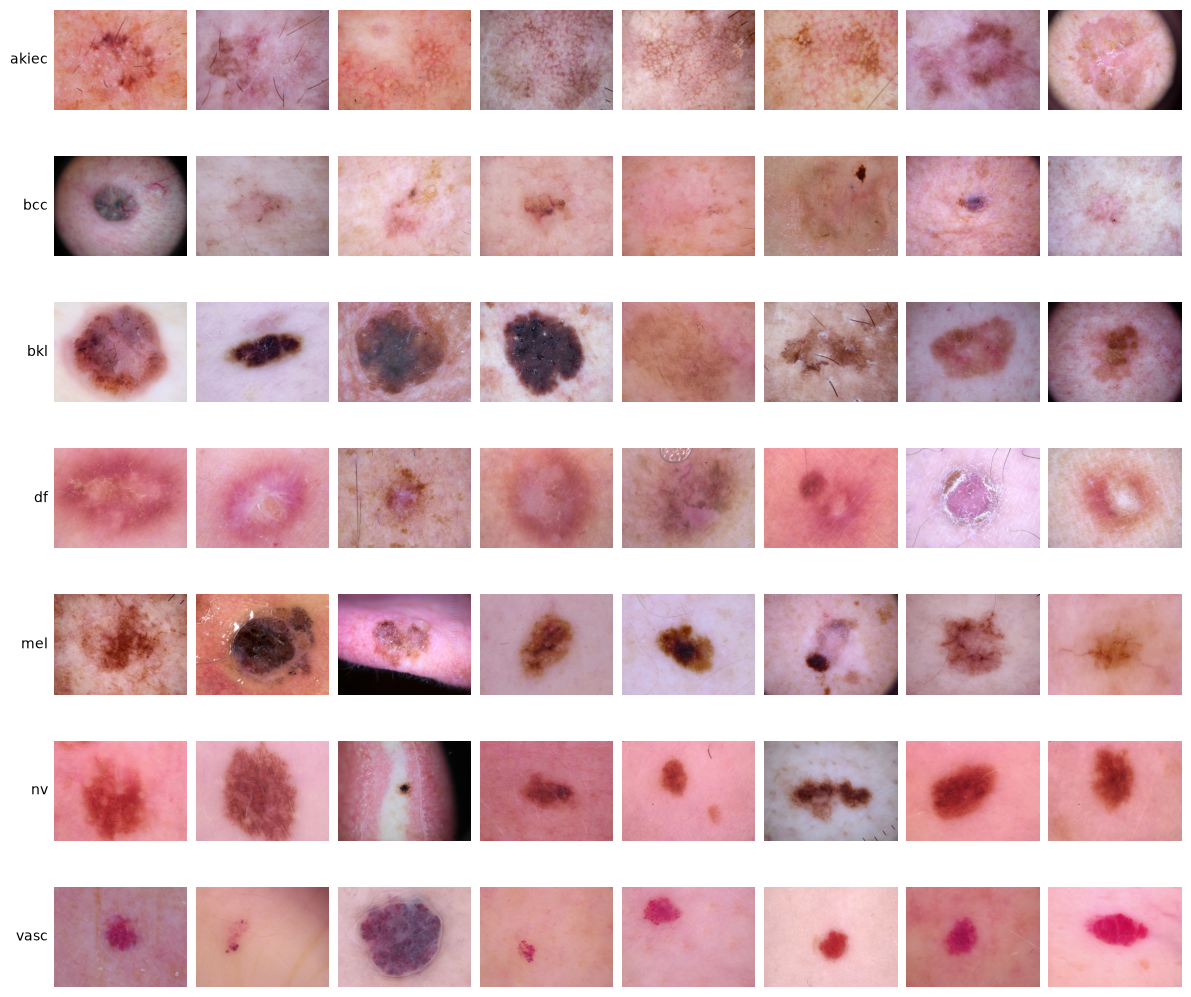

In [5]:
samples = train.unique("lesion_id", keep="first", maintain_order=True)

kx.plot(
    samples["image_path"].to_list(),
    samples["dx"].cast(pl.String).to_list(),
    "imgrid",
    n=8,
    seed=SEED,
    interpolation="antialiased",
);

### 1.2 Variation between images of the same lesion

In [6]:
train.filter(pl.len().over("lesion_id") > 1).drop(pl.selectors.matches("path"))

lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
str,str,enum,str,f64,str,str,str
"""HAM_0000118""","""ISIC_0027419""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern"""
"""HAM_0000118""","""ISIC_0025030""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern"""
"""HAM_0002730""","""ISIC_0026769""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern"""
"""HAM_0002730""","""ISIC_0025661""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern"""
"""HAM_0001466""","""ISIC_0031633""","""bkl""","""histo""",75.0,"""male""","""ear""","""vidir_modern"""
…,…,…,…,…,…,…,…
"""HAM_0002867""","""ISIC_0033084""","""akiec""","""histo""",40.0,"""male""","""abdomen""","""vidir_modern"""
"""HAM_0002867""","""ISIC_0033550""","""akiec""","""histo""",40.0,"""male""","""abdomen""","""vidir_modern"""
"""HAM_0002867""","""ISIC_0033536""","""akiec""","""histo""",40.0,"""male""","""abdomen""","""vidir_modern"""


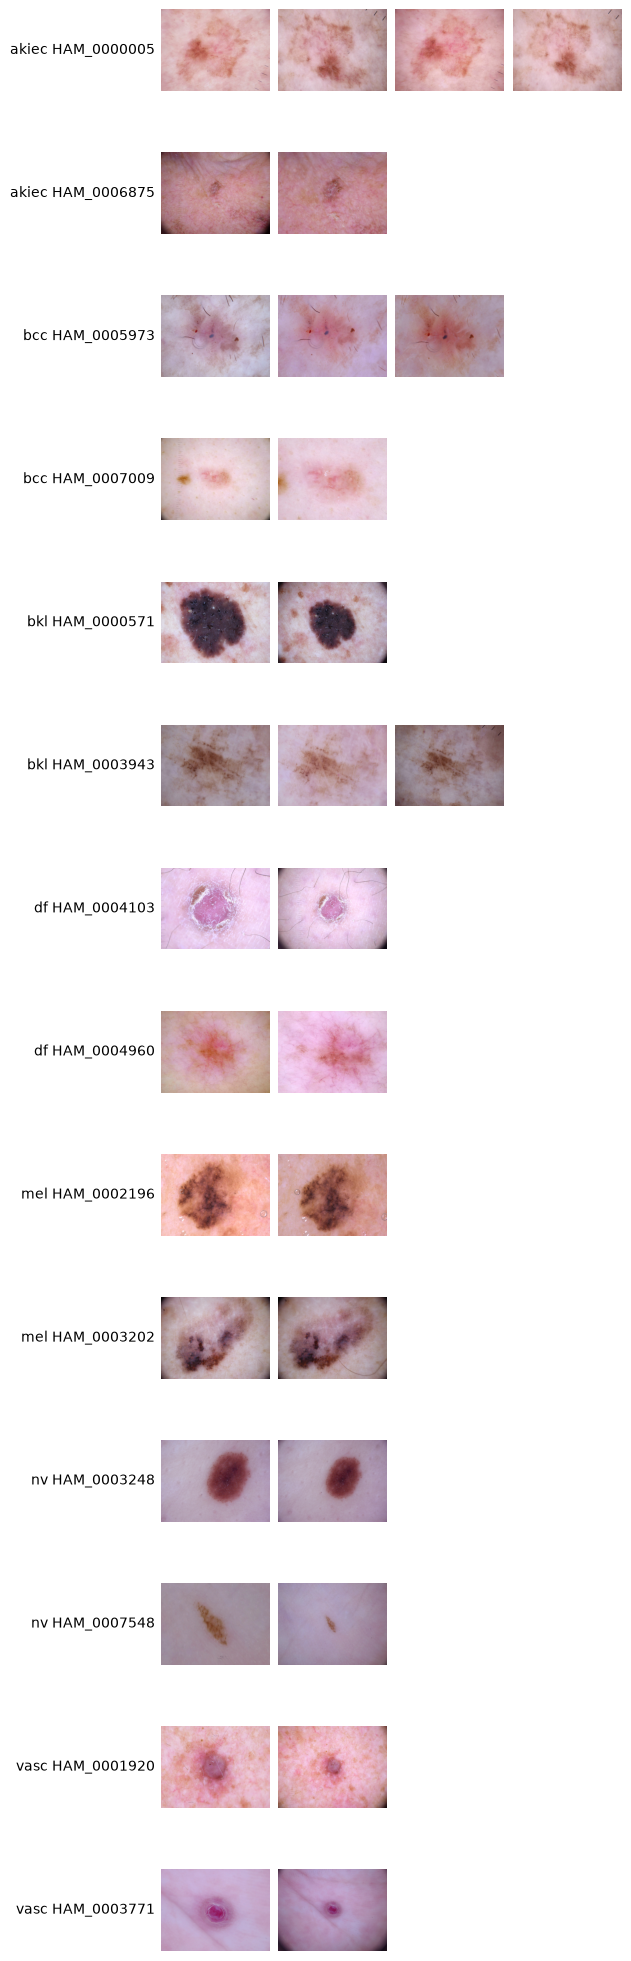

In [7]:
multi_image = train.filter(pl.len().over("lesion_id") > 1)
lesions = (
    multi_image.unique("lesion_id", keep="first", maintain_order=True)
    .filter(pl.int_range(pl.len()).shuffle(seed=SEED).over("dx") < 2)
    .select("lesion_id")
)
lesion_images = multi_image.join(lesions, on="lesion_id", maintain_order="left").with_columns(
    pl.concat_str(pl.col("dx").cast(pl.String), "lesion_id", separator=" ").alias("label")
)

kx.plot(
    lesion_images["image_path"].to_list(),
    lesion_images["label"].to_list(),
    "imgrid",
    n=4,
    seed=SEED,
    interpolation="antialiased",
);

## 2. Pixel statistics

In [8]:
FEATURES_PATH = ROOT / "output" / "eda" / "image_features.parquet"
COLOUR = {"mean_r": "Red", "mean_g": "Green", "mean_b": "Blue"}
APPEARANCE = {"brightness": "Brightness", "contrast": "Contrast", "saturation": "Saturation"}


def image_features(path: str) -> dict[str, float]:
    bgr = cv2.resize(cv2.imread(path), (224, 224), interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    grey = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    return {
        "mean_r": bgr[..., 2].mean() / 255,
        "mean_g": bgr[..., 1].mean() / 255,
        "mean_b": bgr[..., 0].mean() / 255,
        "brightness": hsv[..., 2].mean() / 255,
        "contrast": grey.std() / 255,
        "saturation": hsv[..., 1].mean() / 255,
    }


if FEATURES_PATH.exists():
    pixel_features = pl.read_parquet(FEATURES_PATH)
else:
    paths = train["image_path"].to_list()
    with ThreadPoolExecutor() as pool:
        rows = list(tqdm(pool.map(image_features, paths), total=len(paths)))
    pixel_features = pl.DataFrame(rows).with_columns(train["image_id"])
    FEATURES_PATH.parent.mkdir(parents=True, exist_ok=True)
    pixel_features.write_parquet(FEATURES_PATH)

features = train.join(pixel_features, on="image_id", validate="1:1")


def plot_measures(measures: dict[str, str], group: str, data: pl.DataFrame = features, prefix: str = "") -> None:
    labels = data[group].cast(pl.String).to_list()
    for ax, (column, title) in zip(kx.grid(len(measures)), measures.items(), strict=True):
        kx.plot(data[column].to_numpy(), spec="box-rot", by=labels, ax=ax, title=f"{prefix}{title}", showfliers=False)
        ax.set_xlabel("")


def median_table(measures: dict[str, str], *groups: str) -> pl.DataFrame:
    return features.group_by(groups).agg(pl.len().alias("images"), pl.col(*measures).median().round(3)).sort(groups)

### 2.1 Colour by class

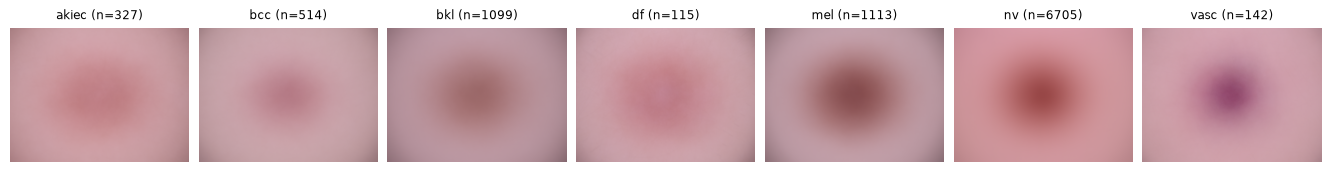

In [9]:
sample_paths = train["image_path"].to_list()
sample_labels = train["dx"].cast(pl.String).to_list()

kx.plot(sample_paths, sample_labels, "meanimg", interpolation="antialiased");

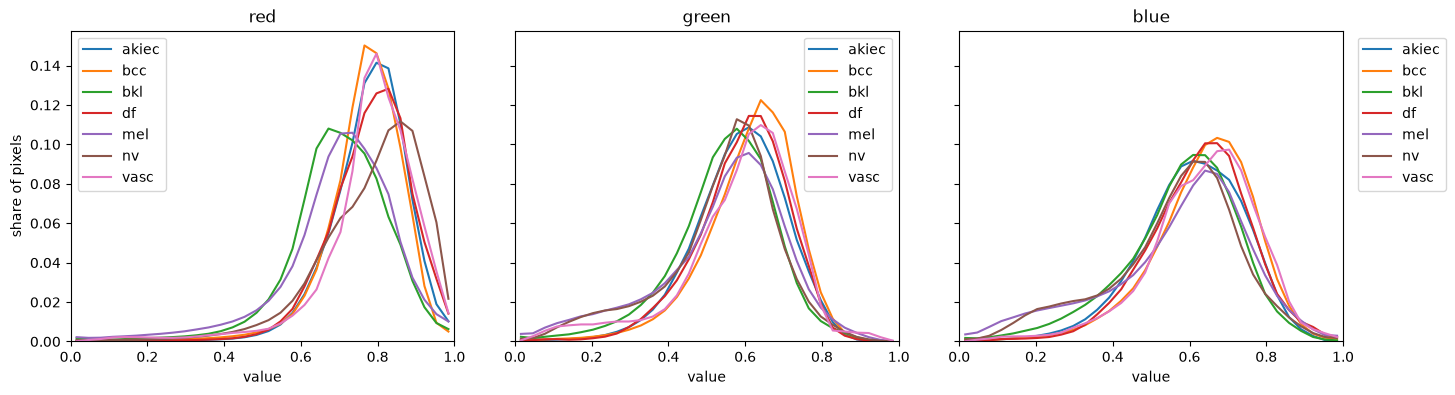

In [10]:
kx.plot(sample_paths, sample_labels, "colorhist-leg");

dx,images,mean_r,mean_g,mean_b
enum,u32,f64,f64,f64
"""nv""",6705,0.798,0.538,0.56
"""mel""",1113,0.694,0.538,0.567
"""bkl""",1099,0.691,0.546,0.577
"""bcc""",514,0.769,0.612,0.639
"""akiec""",327,0.78,0.584,0.6
"""vasc""",142,0.772,0.596,0.639
"""df""",115,0.791,0.594,0.626


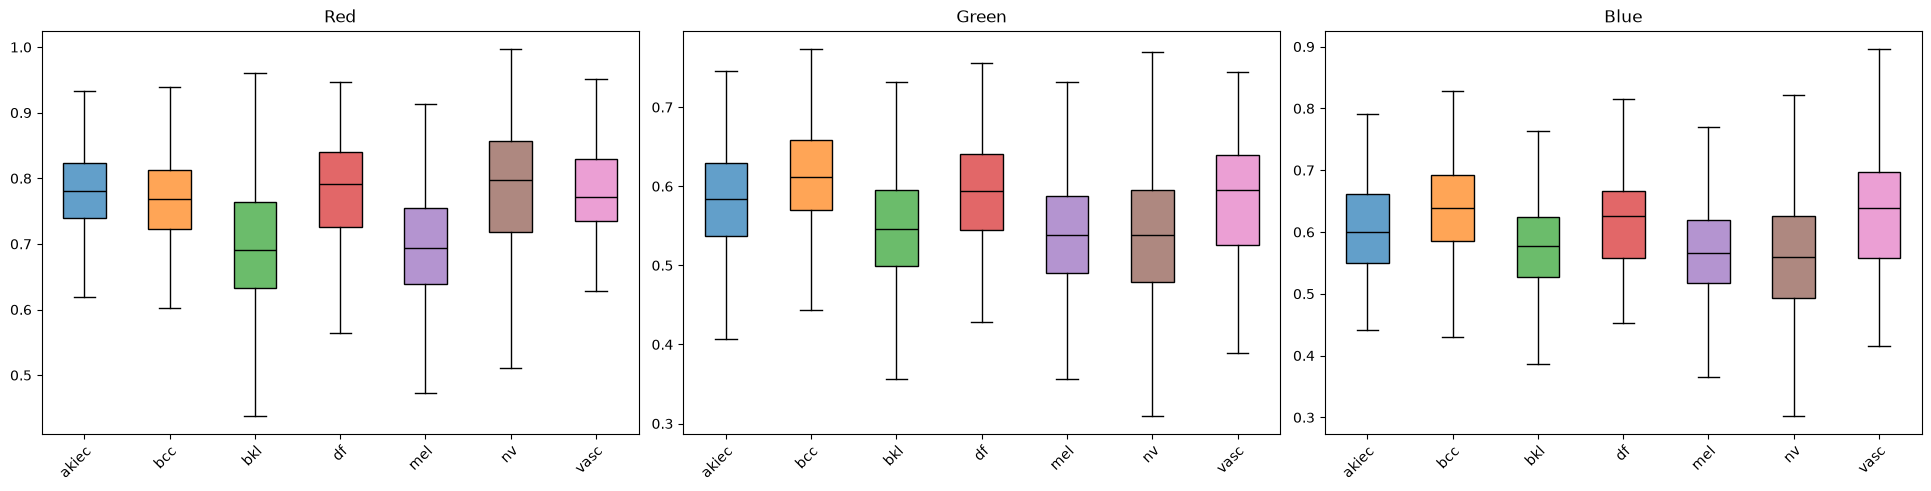

In [11]:
plot_measures(COLOUR, "dx")
median_table(COLOUR, "dx")

### 2.2 Brightness, contrast and saturation by class

dx,images,brightness,contrast,saturation
enum,u32,f64,f64,f64
"""nv""",6705,0.799,0.103,0.36
"""mel""",1113,0.697,0.126,0.25
"""bkl""",1099,0.694,0.09,0.226
"""bcc""",514,0.77,0.077,0.215
"""akiec""",327,0.78,0.084,0.264
"""vasc""",142,0.776,0.091,0.249
"""df""",115,0.792,0.077,0.245


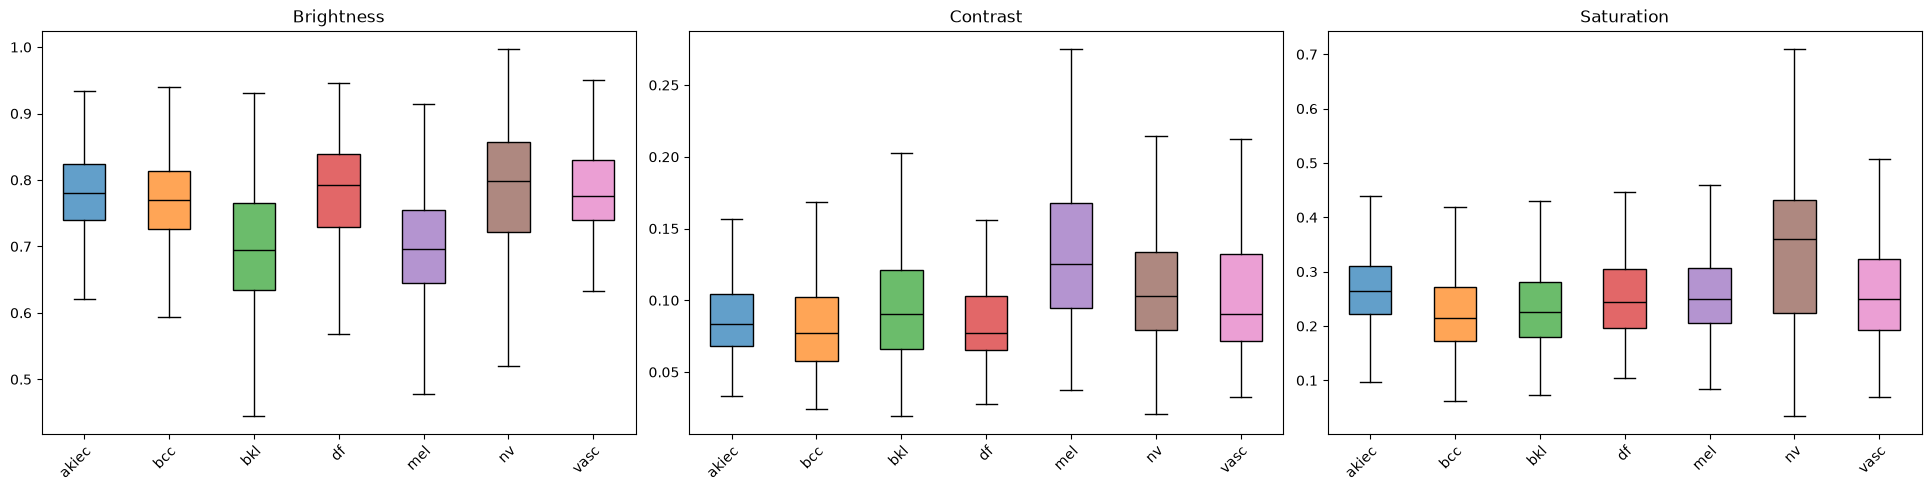

In [12]:
plot_measures(APPEARANCE, "dx")
median_table(APPEARANCE, "dx")

### 2.3 Brightness, contrast and saturation by source

dataset,images,brightness,contrast,saturation
str,u32,f64,f64,f64
"""rosendahl""",2259,0.751,0.088,0.227
"""vidir_modern""",3363,0.693,0.115,0.211
"""vidir_molemax""",3954,0.839,0.096,0.42
"""vienna_dias""",439,0.753,0.144,0.32


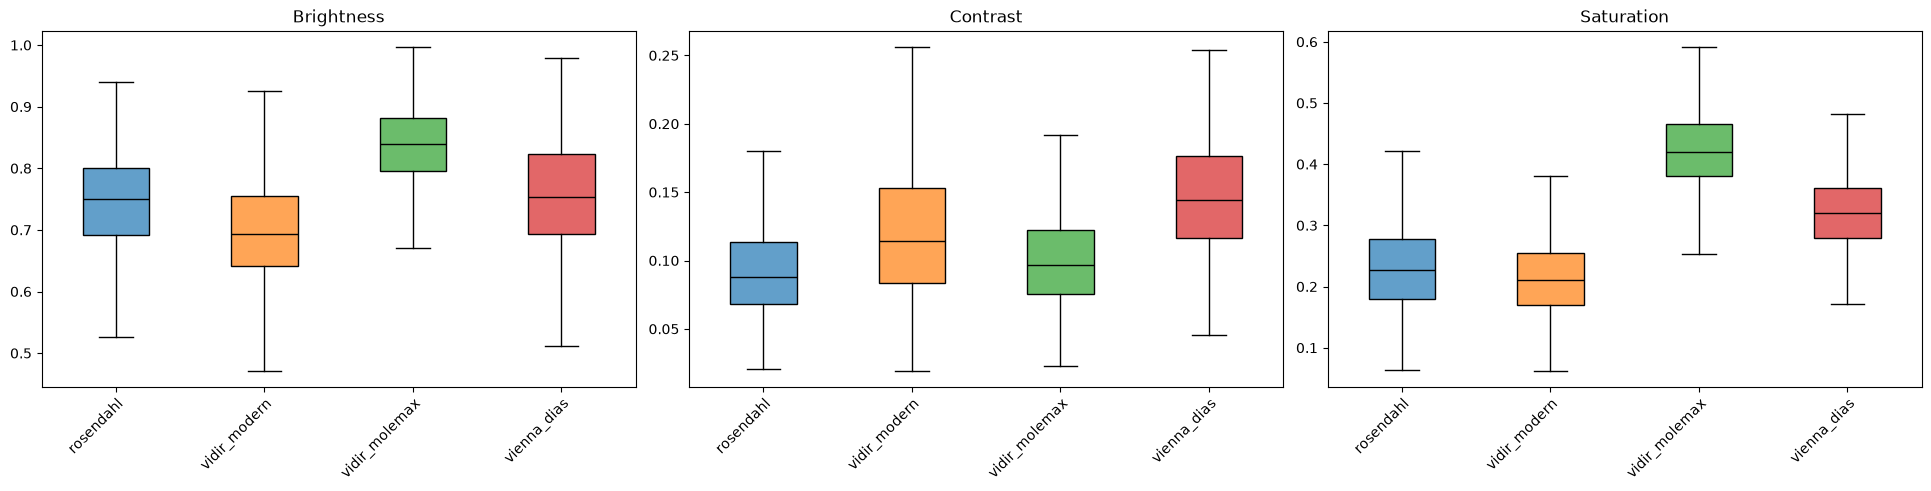

In [13]:
plot_measures(APPEARANCE, "dataset")
median_table(APPEARANCE, "dataset")

dataset,dx,images,brightness,contrast,saturation
str,enum,u32,f64,f64,f64
"""rosendahl""","""nv""",803,0.75,0.095,0.21
"""rosendahl""","""mel""",342,0.742,0.102,0.262
"""vidir_modern""","""nv""",1832,0.695,0.115,0.198
"""vidir_modern""","""mel""",680,0.675,0.13,0.235
"""vidir_molemax""","""nv""",3720,0.841,0.097,0.423
"""vidir_molemax""","""mel""",24,0.793,0.153,0.387
"""vienna_dias""","""nv""",350,0.768,0.14,0.313
"""vienna_dias""","""mel""",67,0.682,0.174,0.337


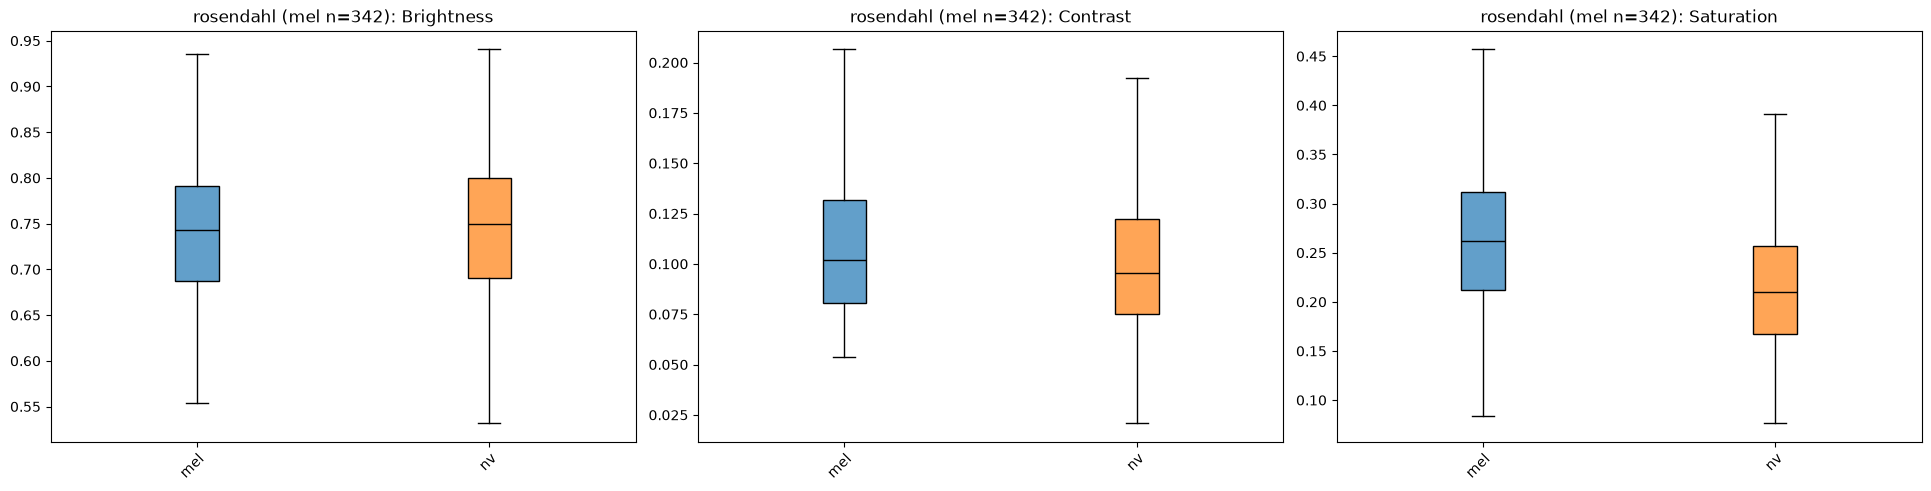

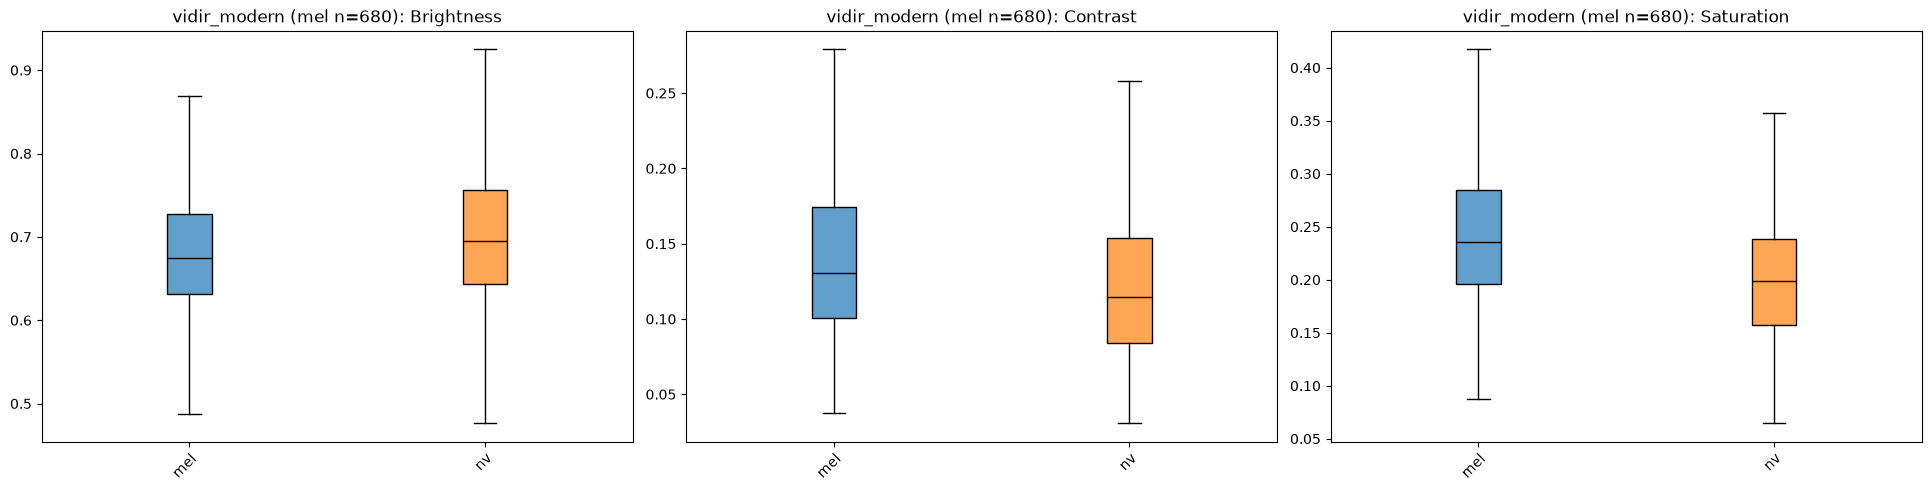

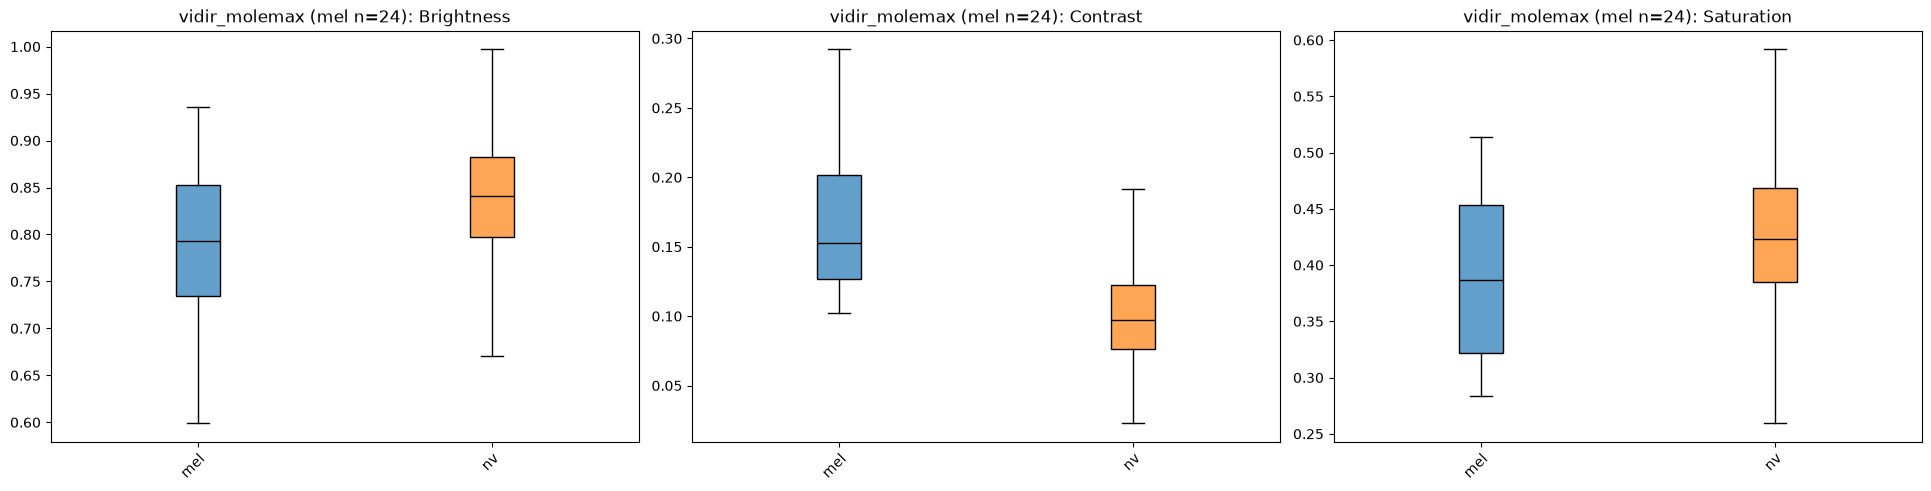

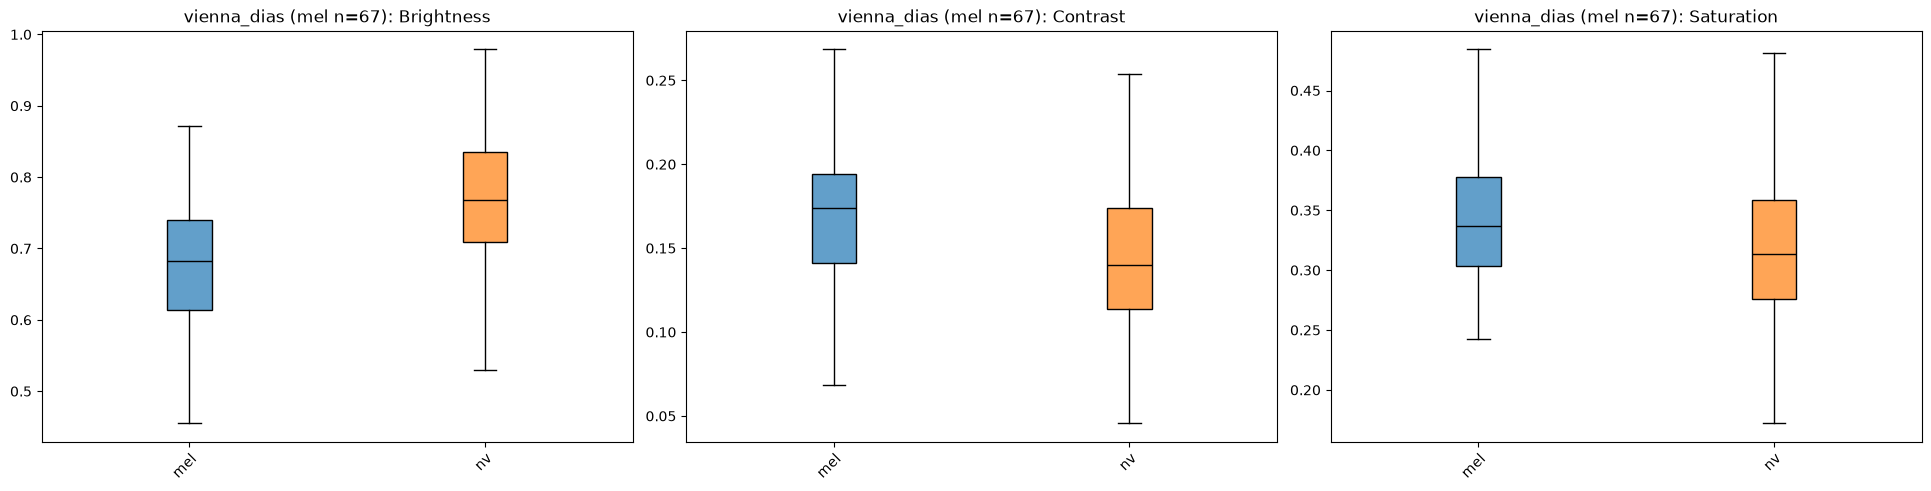

In [14]:
for src in features["dataset"].unique().sort():
    src_df = features.filter((pl.col("dataset") == src) & pl.col("dx").is_in(["mel", "nv"]))
    n_mel = src_df.filter(pl.col("dx") == "mel").height
    plot_measures(APPEARANCE, "dx", src_df, prefix=f"{src} (mel n={n_mel}): ")

median_table(APPEARANCE, "dataset", "dx").filter(pl.col("dx").is_in(["mel", "nv"]))

## 3. Normalisation

### 3.1 Mean and std on HAM10000 train

In [15]:
def channel_moments(path: str) -> tuple[np.ndarray, np.ndarray]:
    bgr = cv2.resize(cv2.imread(path), (224, 224), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB) / 255
    return rgb.mean(axis=(0, 1)), (rgb**2).mean(axis=(0, 1))


with ThreadPoolExecutor() as pool:
    means, squares = map(np.array, zip(*pool.map(channel_moments, train["image_path"].to_list()), strict=True))

HAM_MEAN = means.mean(axis=0)
HAM_STD = np.sqrt(squares.mean(axis=0) - HAM_MEAN**2)
print(f"mean={HAM_MEAN.round(3)} std={HAM_STD.round(3)}")

mean=[0.764 0.546 0.571] std=[0.141 0.152 0.17 ]


### 3.2 Comparison with ImageNet

channel,ham_mean,imagenet_mean,ham_std,imagenet_std
str,f64,f64,f64,f64
"""Red""",0.764,0.485,0.141,0.229
"""Green""",0.546,0.456,0.152,0.224
"""Blue""",0.571,0.406,0.17,0.225


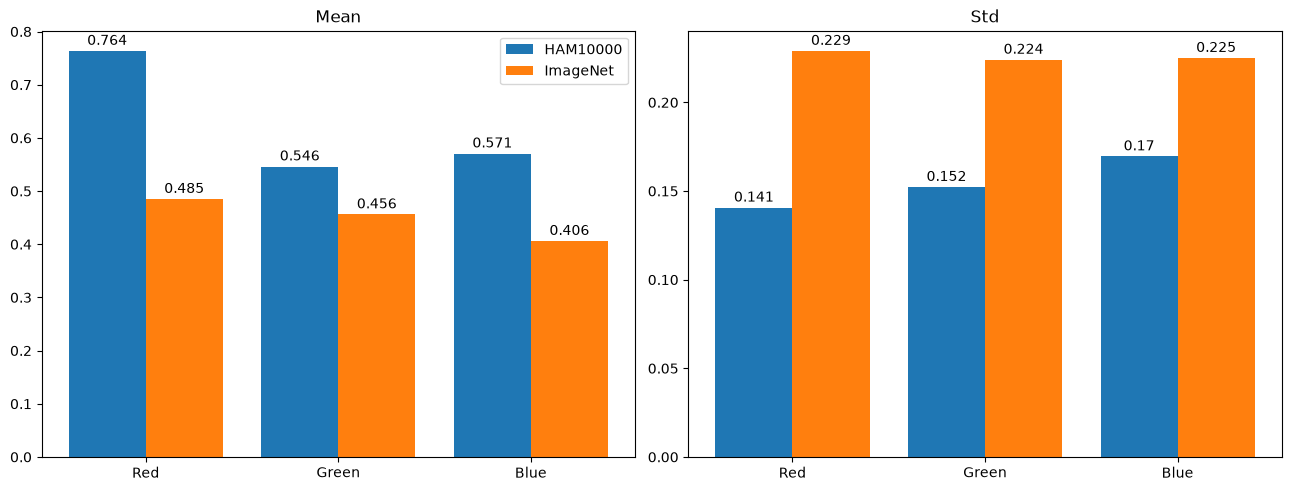

In [16]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])
CHANNELS = ["Red", "Green", "Blue"]

ax_mean, ax_std = kx.grid(2)
kx.plot(CHANNELS, pl.Series("HAM10000", HAM_MEAN), pl.Series("ImageNet", IMAGENET_MEAN), "bar-leg-ann", ax=ax_mean, title="Mean")
kx.plot(CHANNELS, pl.Series("HAM10000", HAM_STD), pl.Series("ImageNet", IMAGENET_STD), "bar-ann", ax=ax_std, title="Std")

pl.DataFrame(
    {
        "channel": CHANNELS,
        "ham_mean": HAM_MEAN.round(3),
        "imagenet_mean": IMAGENET_MEAN,
        "ham_std": HAM_STD.round(3),
        "imagenet_std": IMAGENET_STD,
    }
)

## 4. Image quality

### 4.1 Sharpness

dataset,dx,images,sharpness
str,enum,u32,f64
"""rosendahl""","""nv""",803,1.861
"""rosendahl""","""mel""",342,2.022
"""rosendahl""","""bkl""",490,2.023
"""rosendahl""","""bcc""",296,1.848
"""rosendahl""","""akiec""",295,1.949
…,…,…,…
"""vienna_dias""","""mel""",67,2.177
"""vienna_dias""","""bkl""",10,1.98
"""vienna_dias""","""bcc""",5,2.201


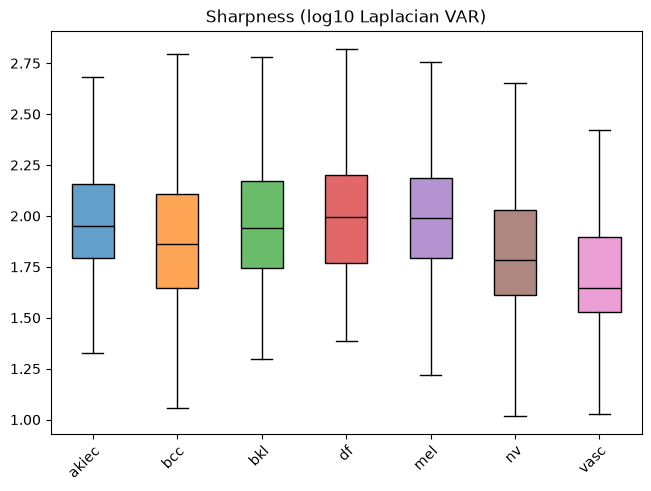

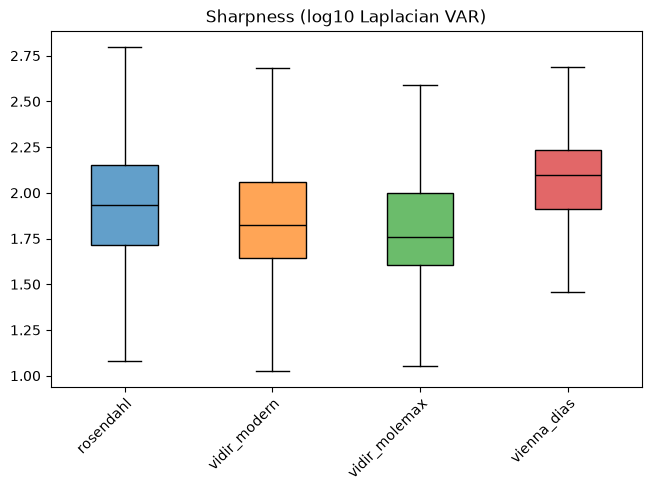

In [17]:
QUALITY_PATH = ROOT / "output" / "eda" / "image_quality.parquet"
SHARPNESS = {"sharpness": "Sharpness (log10 Laplacian VAR)"}


def image_quality(path: str) -> dict[str, float]:
    grey = cv2.resize(cv2.imread(path, cv2.IMREAD_GRAYSCALE), (224, 224), interpolation=cv2.INTER_AREA)

    return {
        "sharpness": np.log10(cv2.Laplacian(grey, cv2.CV_64F).var() + 1),
        "dark_fraction": (grey < 0.05 * 255).mean(),
        "clipped_fraction": (grey > 0.95 * 255).mean(),
    }


if QUALITY_PATH.exists():
    quality = pl.read_parquet(QUALITY_PATH)
else:
    paths = train["image_path"].to_list()
    with ThreadPoolExecutor() as pool:
        rows = list(tqdm(pool.map(image_quality, paths), total=len(paths)))
    quality = pl.DataFrame(rows).with_columns(train["image_id"])
    QUALITY_PATH.parent.mkdir(parents=True, exist_ok=True)
    quality.write_parquet(QUALITY_PATH)

features = train.join(pixel_features, on="image_id", validate="1:1").join(quality, on="image_id", validate="1:1")

plot_measures(SHARPNESS, "dx", features)
plot_measures(SHARPNESS, "dataset", features)
median_table(SHARPNESS, "dataset", "dx")

### 4.2 Exposure

dataset,images,dark,clipped
str,u32,f64,f64
"""rosendahl""",2259,0.017707,0.008411
"""vidir_modern""",3363,0.085935,0.012191
"""vidir_molemax""",3954,0.0,0.0
"""vienna_dias""",439,0.031891,0.009112


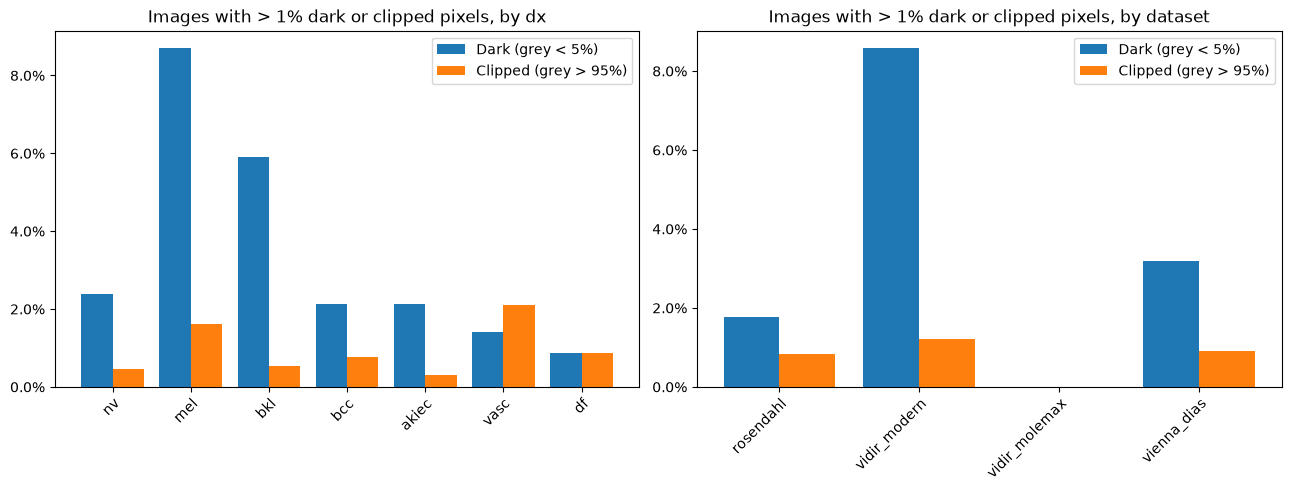

In [18]:
EXPOSURE_THRESHOLD = 0.01


def exposure_rates(group: str) -> pl.DataFrame:
    return (
        features.group_by(group)
        .agg(
            pl.len().alias("images"),
            (pl.col("dark_fraction") > EXPOSURE_THRESHOLD).mean().alias("dark"),
            (pl.col("clipped_fraction") > EXPOSURE_THRESHOLD).mean().alias("clipped"),
        )
        .sort(group)
    )


for ax, group in zip(kx.grid(2), ["dx", "dataset"], strict=True):
    rates = exposure_rates(group)
    kx.plot(
        rates[group].cast(pl.String).to_list(),
        pl.Series("Dark (grey < 5%)", rates["dark"]),
        pl.Series("Clipped (grey > 95%)", rates["clipped"]),
        "bar-leg-pct-rot",
        ax=ax,
        title=f"Images with > 1% dark or clipped pixels, by {group}",
    )

exposure_rates("dataset")

### 4.3 Outlier review

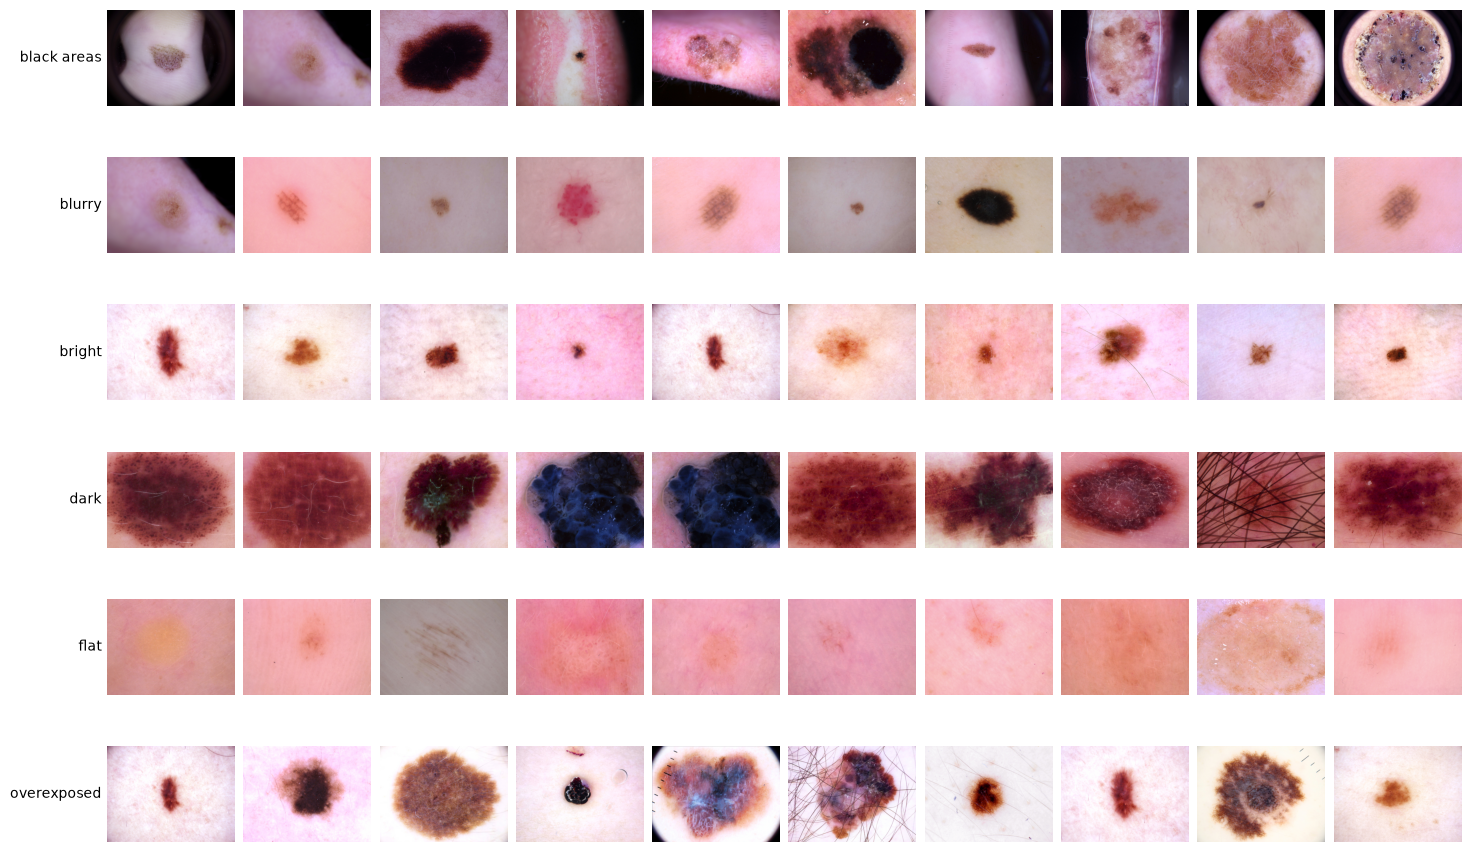

In [19]:
OUTLIERS_PER_CHECK = 10


def mad(column: str) -> pl.Expr:
    deviation = pl.col(column) - pl.col(column).median().over("dataset")
    return deviation / (1.48 * deviation.abs().median().over("dataset"))


OUTLIER_CHECKS = {
    "blurry": -mad("sharpness"),
    "dark": -mad("brightness"),
    "bright": mad("brightness"),
    "flat": -mad("contrast"),
    "black areas": pl.col("dark_fraction"),
    "overexposed": pl.col("clipped_fraction"),
}

outliers = pl.concat(
    [
        features.with_columns(score=score, problem=pl.lit(problem)).top_k(OUTLIERS_PER_CHECK, by="score")
        for problem, score in OUTLIER_CHECKS.items()
    ]
).select("problem", "image_id", "dataset", "dx", pl.col("score").round(2), "image_path")

kx.plot(
    outliers["image_path"].to_list(),
    outliers["problem"].to_list(),
    "imgrid",
    n=OUTLIERS_PER_CHECK,
    interpolation="antialiased",
);

In [20]:
outliers.drop("image_path")

problem,image_id,dataset,dx,score
str,str,str,enum,f64
"""blurry""","""ISIC_0027519""","""vienna_dias""","""nv""",3.45
"""blurry""","""ISIC_0024753""","""vienna_dias""","""nv""",3.24
"""blurry""","""ISIC_0028633""","""vidir_modern""","""nv""",2.94
"""blurry""","""ISIC_0031107""","""rosendahl""","""nv""",2.92
"""blurry""","""ISIC_0026022""","""rosendahl""","""nv""",2.81
…,…,…,…,…
"""overexposed""","""ISIC_0033797""","""vidir_modern""","""nv""",0.24
"""overexposed""","""ISIC_0029027""","""vienna_dias""","""nv""",0.24
"""overexposed""","""ISIC_0028086""","""vidir_modern""","""mel""",0.23


## 5. Artefacts

### 5.1 Dark corner detector

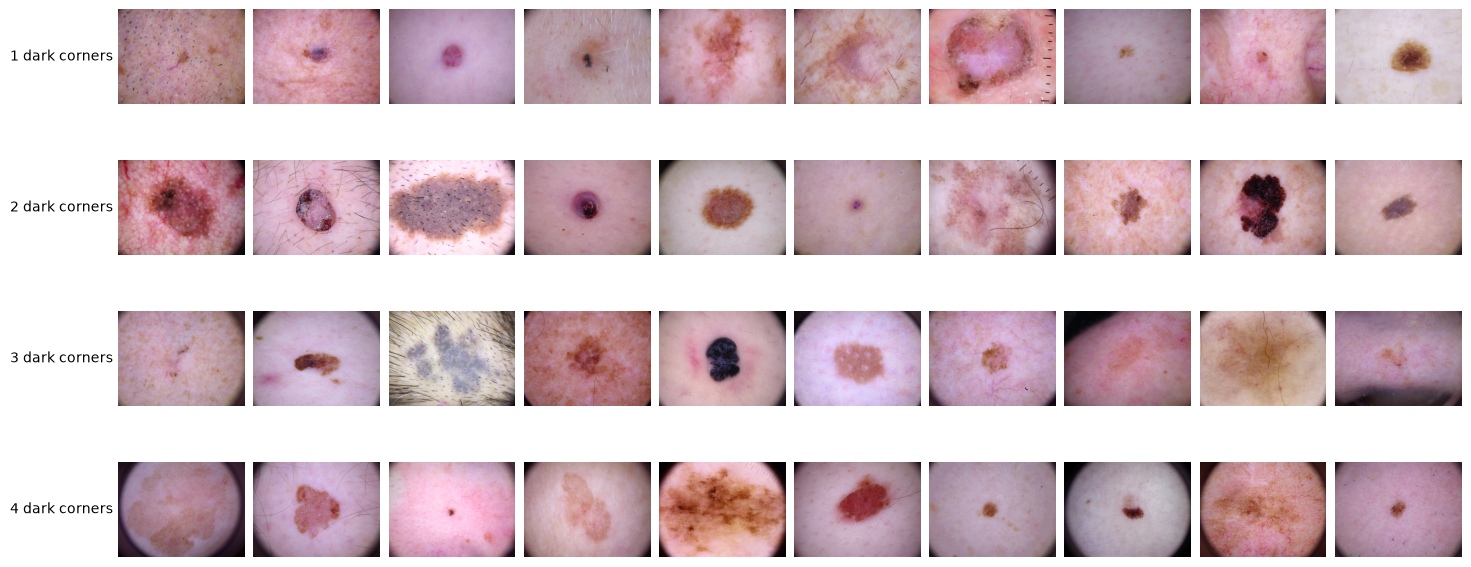

In [21]:
ARTEFACT_SIZE = 350
CORNER_SIZE = 15
REL_DARK = 0.5
DARK_FRAC = 0.8


def corner_score(path: str) -> np.ndarray:
    grey = cv2.resize(cv2.imread(path, cv2.IMREAD_GRAYSCALE), (ARTEFACT_SIZE, ARTEFACT_SIZE), interpolation=cv2.INTER_AREA)
    q = ARTEFACT_SIZE // 4
    patches = [
        grey[:CORNER_SIZE, :CORNER_SIZE],
        grey[:CORNER_SIZE, -CORNER_SIZE:][:, ::-1],
        grey[-CORNER_SIZE:, :CORNER_SIZE][::-1, :],
        grey[-CORNER_SIZE:, -CORNER_SIZE:][::-1, ::-1],
    ]
    return np.array(
        [
            (
                p[(np.mgrid[:CORNER_SIZE, :CORNER_SIZE][0] + np.mgrid[:CORNER_SIZE, :CORNER_SIZE][1]) < CORNER_SIZE]
                < REL_DARK * max(np.median(grey[q:-q, q:-q]), 1)
            ).mean()
            for p in patches
        ]
    )


with ThreadPoolExecutor() as pool:
    scores = np.stack(list(pool.map(corner_score, features["image_path"].to_list())))

dark_count = (scores > DARK_FRAC).sum(axis=1)
features = features.with_columns(
    corner_dark_frac=pl.Series(scores.mean(axis=1)),
    dark_corners=pl.Series(dark_count),
    has_dark_corners=pl.Series(dark_count > 0),
)

corner_samples = features.filter(pl.col("has_dark_corners"))
kx.plot(
    corner_samples["image_path"].to_list(),
    corner_samples.select(pl.format("{} dark corners", "dark_corners")).to_series().to_list(),
    "imgrid",
    n=10,
    seed=SEED,
    interpolation="antialiased",
);

In [22]:
features["dark_corners"].value_counts().sort("dark_corners")

dark_corners,count
i64,u32
0,8761
1,224
2,191
3,150
4,689


### 5.2 Hair detector

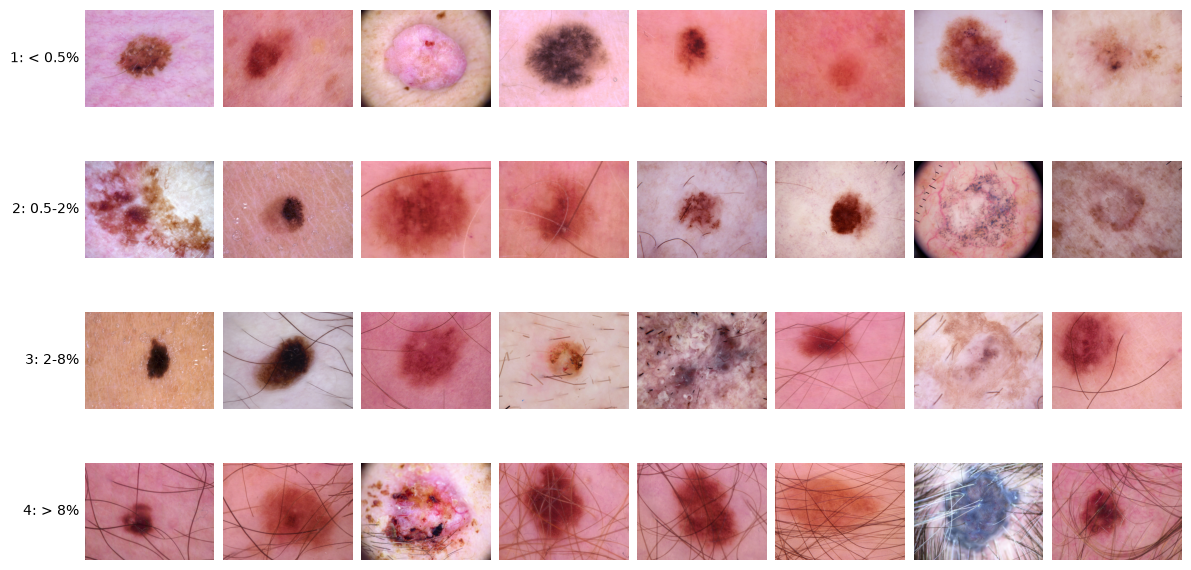

In [23]:
# Adapted from https://github.com/sopheakchan/dull-razor-algorithm  (no license specified)
# Method: Lee et al. (1997), "DullRazor", Comput. Biol. Med. 27(6).
HAIR_THRESHOLD = 0.02
MIN_SKIN_BRIGHTNESS = 0.2
LESION_MARGIN = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))


# function to apply dull razor algorithm to an image
def dull_razor(path: str, mask_path: str) -> float:
    # convert to grayscale
    grayScale = cv2.resize(cv2.imread(path, cv2.IMREAD_GRAYSCALE), (ARTEFACT_SIZE, ARTEFACT_SIZE), interpolation=cv2.INTER_AREA)

    # blackhat filtering (shape and size)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    blackhat = cv2.morphologyEx(grayScale, cv2.MORPH_BLACKHAT, kernel)

    # binary thresholding (mask)
    _, mask = cv2.threshold(blackhat, 20, 255, cv2.THRESH_BINARY)

    # lesion + skin exclusion
    lesion_mask = cv2.resize(cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE), grayScale.shape[::-1], interpolation=cv2.INTER_NEAREST)
    lesion = cv2.dilate((lesion_mask > 0).astype(np.uint8), LESION_MARGIN).astype(bool)
    skin = ~lesion & (grayScale > MIN_SKIN_BRIGHTNESS * 255)

    return float((mask > 0)[skin].mean()) if skin.any() else 0.0


with ThreadPoolExecutor() as pool:
    hair = pl.Series(pool.map(dull_razor, features["image_path"].to_list(), features["mask_path"].to_list()))

features = features.with_columns(hair_fraction=hair, has_hair=hair > HAIR_THRESHOLD)

hair_bins = features["hair_fraction"].cut(
    [0.005, HAIR_THRESHOLD, 0.08],
    labels=["1: < 0.5%", "2: 0.5-2%", "3: 2-8%", "4: > 8%"],
)
kx.plot(
    features["image_path"].to_list(),
    hair_bins.cast(pl.String).to_list(),
    "imgrid",
    n=8,
    seed=SEED,
    interpolation="antialiased",
);

In [24]:
hair_bins.value_counts().sort("hair_fraction")

hair_fraction,count
enum,u32
"""1: < 0.5%""",6942
"""2: 0.5-2%""",1810
"""3: 2-8%""",971
"""4: > 8%""",292


### 5.3 Prevalence by class and site

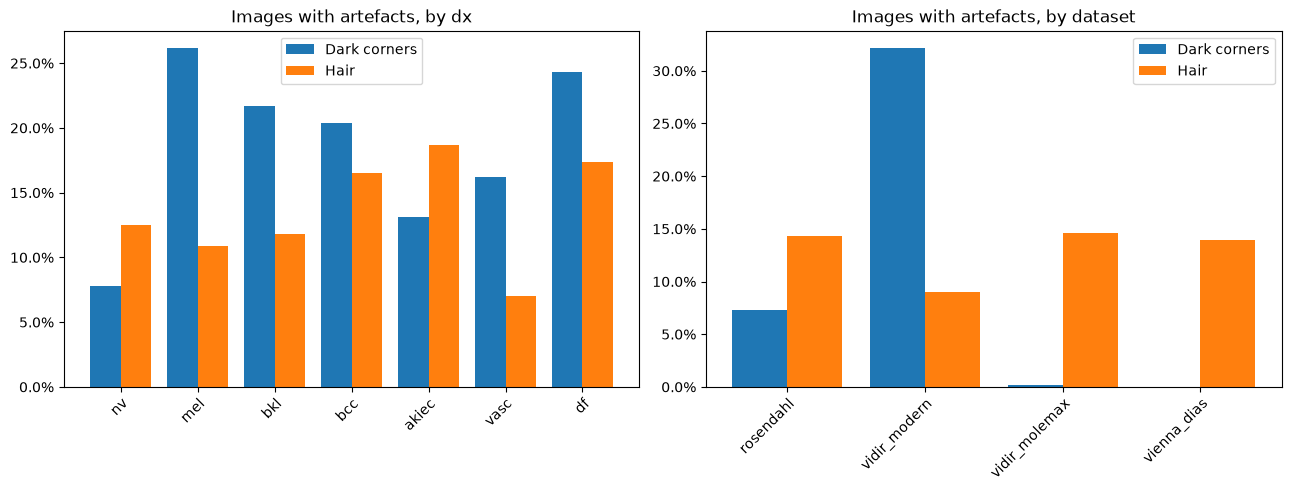

In [25]:
ARTEFACTS = {"has_dark_corners": "Dark corners", "has_hair": "Hair"}


def artefact_rates(*groups: str) -> pl.DataFrame:
    return features.group_by(groups).agg(pl.len().alias("images"), pl.col(*ARTEFACTS).mean().round(3)).sort(groups)


for ax, group in zip(kx.grid(2), ["dx", "dataset"], strict=True):
    rates = artefact_rates(group)
    kx.plot(
        rates[group].cast(pl.String).to_list(),
        *(pl.Series(label, rates[column]) for column, label in ARTEFACTS.items()),
        "bar-leg-pct-rot",
        ax=ax,
        title=f"Images with artefacts, by {group}",
    )

In [26]:
artefact_rates("dataset", "dx")

dataset,dx,images,has_dark_corners,has_hair
str,enum,u32,f64,f64
"""rosendahl""","""nv""",803,0.054,0.086
"""rosendahl""","""mel""",342,0.082,0.152
"""rosendahl""","""bkl""",490,0.098,0.169
"""rosendahl""","""bcc""",296,0.047,0.179
"""rosendahl""","""akiec""",295,0.098,0.197
…,…,…,…,…
"""vienna_dias""","""mel""",67,0.0,0.224
"""vienna_dias""","""bkl""",10,0.0,0.2
"""vienna_dias""","""bcc""",5,0.0,0.4


## 6. Lesion vs surrounding skin

### 6.1 Colour by class

dx,images,delta_r,delta_g,delta_b
enum,u32,f64,f64,f64
"""nv""",6705,-0.141,-0.247,-0.29
"""mel""",1113,-0.133,-0.251,-0.31
"""bkl""",1099,-0.063,-0.129,-0.176
"""bcc""",514,-0.035,-0.094,-0.094
"""akiec""",327,-0.024,-0.09,-0.102
"""vasc""",142,-0.129,-0.302,-0.2
"""df""",115,-0.055,-0.133,-0.133


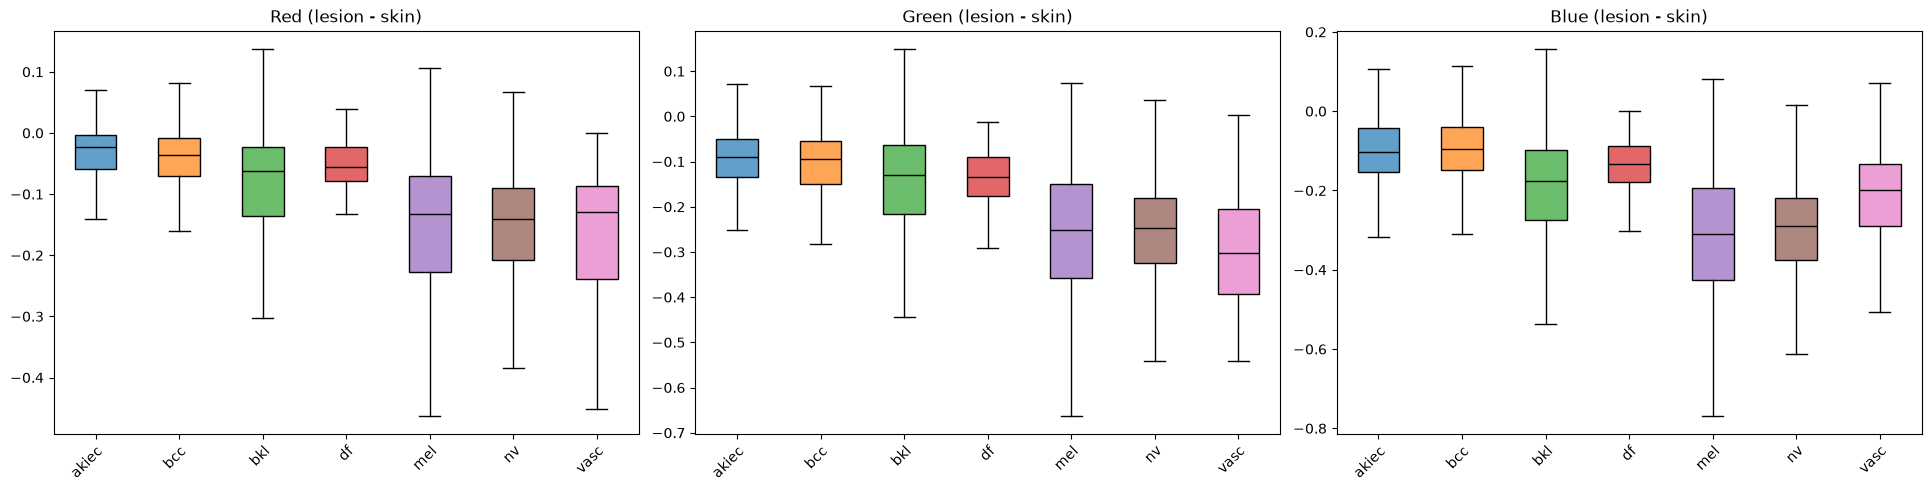

In [27]:
LESION_SIZE = 224
RING_INNER = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
RING_OUTER = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (45, 45))
MIN_REGION_PIXELS = 200

COLOUR_DIFFERENCE = {
    "delta_r": "Red (lesion - skin)",
    "delta_g": "Green (lesion - skin)",
    "delta_b": "Blue (lesion - skin)",
}
LESION_CONTRAST = {
    "delta_e": "Colour distance (Delta E)",
    "luminance_contrast": "Luminance contrast",
}
LESION_MEASURES = COLOUR_DIFFERENCE | LESION_CONTRAST


def ls_f(path: str, mask_path: str) -> dict[str, float | None]:
    bgr = cv2.resize(cv2.imread(path), (LESION_SIZE, LESION_SIZE), interpolation=cv2.INTER_AREA)
    lesion = (
        cv2.resize(cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE), (LESION_SIZE, LESION_SIZE), interpolation=cv2.INTER_NEAREST) > 0
    ).astype(np.uint8)
    out = (
        (cv2.dilate(lesion, RING_OUTER) > 0)
        & (cv2.dilate(lesion, RING_INNER) == 0)
        & (cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY) > MIN_SKIN_BRIGHTNESS * 255)
    )
    inside = lesion > 0
    if inside.sum() < MIN_REGION_PIXELS or out.sum() < MIN_REGION_PIXELS:
        return dict.fromkeys(LESION_MEASURES)

    lab = cv2.cvtColor((bgr / 255).astype(np.float32), cv2.COLOR_BGR2Lab)
    bgr_delta = (np.median(bgr[inside], axis=0) - np.median(bgr[out], axis=0)) / 255
    lab_lesion, lab_skin = np.median(lab[inside], axis=0), np.median(lab[out], axis=0)
    return {
        "delta_r": float(bgr_delta[2]),
        "delta_g": float(bgr_delta[1]),
        "delta_b": float(bgr_delta[0]),
        "delta_e": float(np.linalg.norm(lab_lesion - lab_skin)),
        "luminance_contrast": float((lab_skin[0] - lab_lesion[0]) / lab_skin[0]),
    }


with ThreadPoolExecutor() as pool:
    rows = list(pool.map(ls_f, features["image_path"].to_list(), features["mask_path"].to_list()))

features = features.drop(LESION_MEASURES, strict=False).hstack(
    pl.DataFrame(rows, schema=dict.fromkeys(LESION_MEASURES, pl.Float64))
)
lesion_features = features.drop_nulls(list(LESION_MEASURES))

plot_measures(COLOUR_DIFFERENCE, "dx", lesion_features)
median_table(COLOUR_DIFFERENCE, "dx")

### 6.2 Contrast by class

dx,images,delta_e,luminance_contrast
enum,u32,f64,f64
"""nv""",6705,26.619,0.292
"""mel""",1113,28.128,0.302
"""bkl""",1099,16.223,0.163
"""bcc""",514,11.008,0.104
"""akiec""",327,10.924,0.095
"""vasc""",142,32.35,0.326
"""df""",115,14.975,0.142


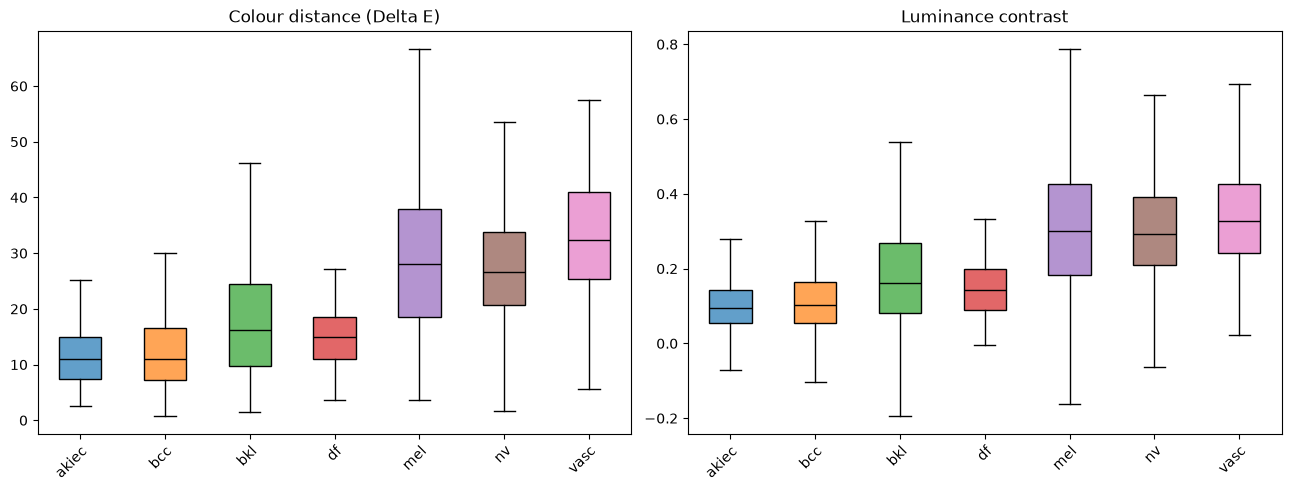

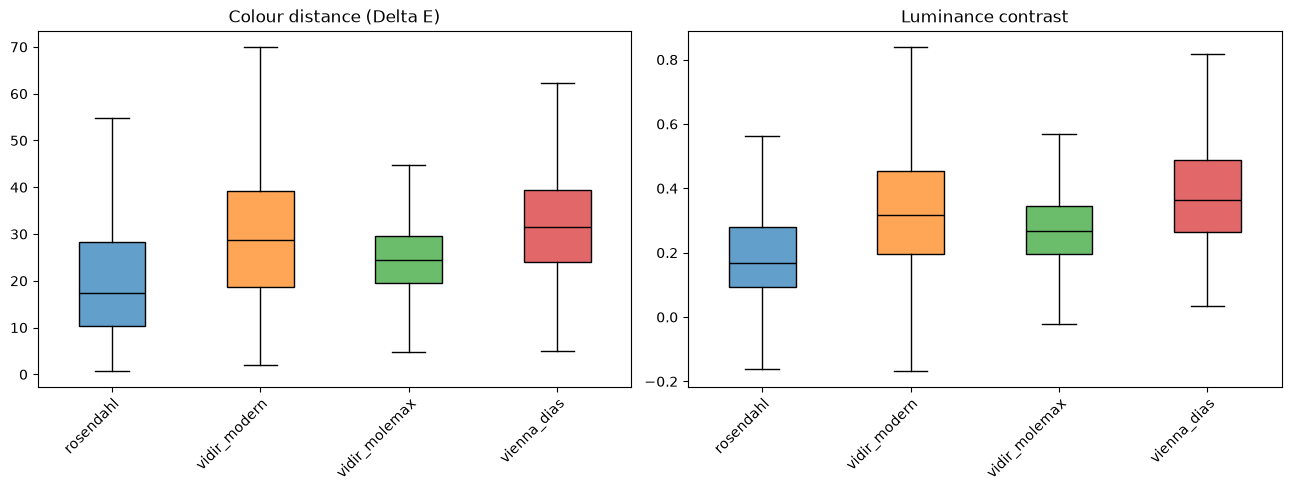

In [28]:
plot_measures(LESION_CONTRAST, "dx", lesion_features)
plot_measures(LESION_CONTRAST, "dataset", lesion_features)
median_table(LESION_CONTRAST, "dx")

In [29]:
median_table(LESION_CONTRAST, "dataset", "dx").filter(pl.col("dx").is_in(["mel", "nv"]))

dataset,dx,images,delta_e,luminance_contrast
str,enum,u32,f64,f64
"""rosendahl""","""nv""",803,26.971,0.267
"""rosendahl""","""mel""",342,23.082,0.209
"""vidir_modern""","""nv""",1832,33.014,0.364
"""vidir_modern""","""mel""",680,29.696,0.337
"""vidir_molemax""","""nv""",3720,24.631,0.27
"""vidir_molemax""","""mel""",24,32.257,0.352
"""vienna_dias""","""nv""",350,31.76,0.358
"""vienna_dias""","""mel""",67,31.9,0.422


## Augmentation Table

|  | Augmentation | Params | Why |
|---|---|---|---|
| 1 | `RandomResizedCrop` | 224px, scale 0.7–1.0, ratio 0.75–1.33 | Varies zoom and partly removes dark corners; original images are 600 x 450 |
| 2 | `D4` (flips + 90° rotations) | p=1 | Dermoscopy has no  orientation,helps with robuistness|
| 3 | `Affine` | rotate ±30°, scale 0.9-1.1, shear ≤5°, reflect border, p=0.5 | Adds in-between angles |
| 4 | `ColorJitter`: brightness | x0.85-1.15 | Sources median span 0.69-0.84 |
| 5 | `ColorJitter`: saturation | x0.7-1.4 | sources medians span 0.21-0.42, |
| 6 | `ColorJitter`: contrast | x0.8-1.25 | Sources span 0.088–0.144 |
| 7 | `ColorJitter`: hue | ±0.02 | Colour is diagnosticly important, account for imaging quality|
| 8 | Synthetic vignette | same for every class | Dark corners appear in 26% of mel vs 8% of nv, and 32% of `vidir_modern` vs about 0% of `vidir_molemax` and `vienna_dias` |
| 9 | `GaussianBlur` | sigma <=1.0, p=0.15 | Sharpness varies by source, fine pigmnet structures must be preserved|
| 10 | `ImageCompression` | quality 75–95, p=0.15 | Mild robustness to source differences |
| 11 | `Normalize` | Pretrained: ImageNet mean [0.485, 0.456, 0.406], std [0.229, 0.224, 0.225]. From scratch: HAM mean [0.764, 0.546, 0.571], std [0.141, 0.152, 0.170] | Must match the pretrained weights' expected input |

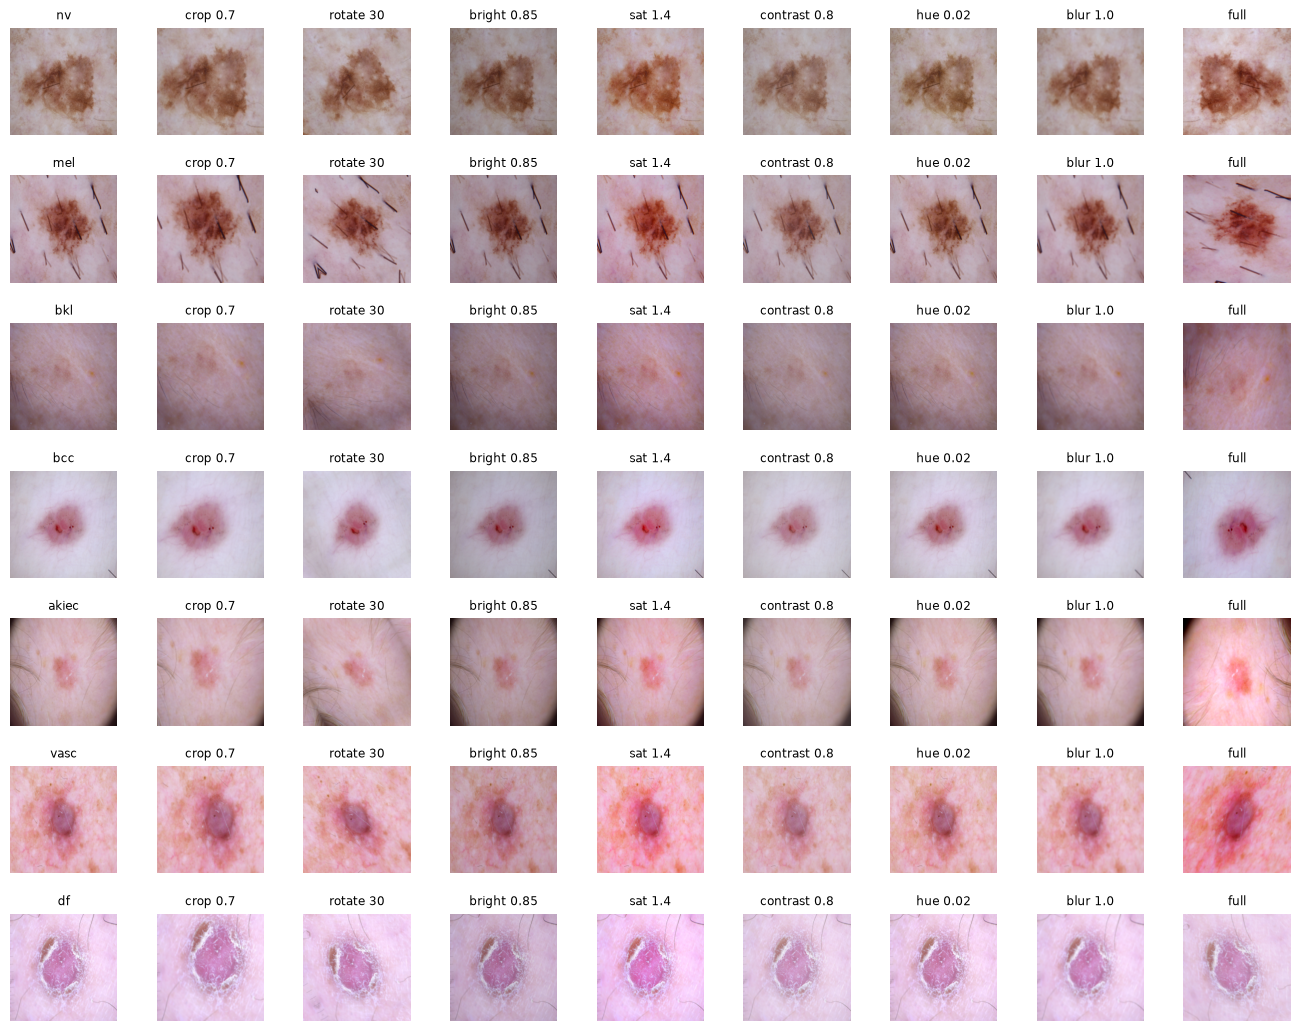

In [33]:
PREVIEW_SIZE = 224


def jitter(**strength: tuple[float, float]) -> A.ColorJitter:
    return A.ColorJitter(**({"brightness": (1, 1), "contrast": (1, 1), "saturation": (1, 1), "hue": (0, 0)} | strength), p=1)


PREVIEWS = {
    "crop 0.7": A.RandomResizedCrop(size=(PREVIEW_SIZE, PREVIEW_SIZE), scale=(0.7, 0.7), ratio=(1, 1), p=1),
    "rotate 30": A.Affine(rotate=(30, 30), border_mode=cv2.BORDER_REFLECT_101, p=1),
    "bright 0.85": jitter(brightness=(0.85, 0.85)),
    "sat 1.4": jitter(saturation=(1.4, 1.4)),
    "contrast 0.8": jitter(contrast=(0.8, 0.8)),
    "hue 0.02": jitter(hue=(0.02, 0.02)),
    "blur 1.0": A.GaussianBlur(sigma_limit=(1.0, 1.0), blur_limit=(5, 5), p=1),
    "full": A.Compose(
        [
            A.RandomResizedCrop(size=(PREVIEW_SIZE, PREVIEW_SIZE), scale=(0.7, 1.0), ratio=(0.75, 1.33)),
            A.D4(p=1),
            A.Affine(rotate=(-30, 30), scale=(0.9, 1.1), shear=(-5, 5), border_mode=cv2.BORDER_REFLECT_101, p=0.5),
            A.ColorJitter(brightness=(0.85, 1.15), contrast=(0.8, 1.25), saturation=(0.7, 1.4), hue=(-0.02, 0.02), p=1),
            A.GaussianBlur(sigma_limit=(0.1, 1.0), p=0.15),
            A.ImageCompression(quality_range=(75, 95), p=0.15),
        ],
        seed=SEED,
    ),
}

preview_samples = (
    train.unique("lesion_id", keep="first", maintain_order=True)
    .filter(pl.int_range(pl.len()).shuffle(seed=SEED).over("dx") == 0)
    .sort("dx")
)

images, titles = [], []
for path, dx in zip(preview_samples["image_path"], preview_samples["dx"].cast(pl.String), strict=True):
    rgb = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    original = cv2.resize(rgb, (PREVIEW_SIZE, PREVIEW_SIZE), interpolation=cv2.INTER_AREA)
    images += [original, *(transform(image=original)["image"] for transform in PREVIEWS.values())]
    titles += [dx, *PREVIEWS]

kx.plot(images, titles, "imgrid", idx=list(range(len(images))), cols=len(PREVIEWS) + 1, interpolation="antialiased");